# Behavioural anomaly model: training and evaluation

AgentGuard's gateway decides every tool call with deterministic policy. This notebook trains the **advisory** model that looks at *behaviour over time*: an agent that reads far more tickets than any task needs, or drains small refunds that are each allowed on their own. No single call breaks a rule, so policy can't see it.

What happens here:

1. Build per-agent behaviour windows from the real execution trace (read-only).
2. Attach ground truth: which calls were attacks, from the traffic generator's label file (the gateway never sees it).
3. Split by time (train → validation → test), so the model is always judged on traffic from *after* what it learned from.
4. Compare eight detectors: four unsupervised (Isolation Forest, Local Outlier Factor, One-Class SVM, a neural autoencoder), three supervised (gradient boosting, random forest, a neural classifier) and an ensemble.
5. Pick the winner on **validation**, report it on the untouched **test** split, check how it does on attack types it never saw, then save it where the console reads it.

The model is advisory: nothing on the enforcement path imports it (`tests/test_ml.py` checks that).

In [1]:
import json
import os
import warnings
from datetime import datetime, timedelta
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score

from agentguard.ml.detectors import DETECTORS
from agentguard.ml.features import FEATURES, Window, build_windows

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.precision", 3)
SEED = 0

# Where the data comes from. With a database and label file available, windows are rebuilt from the
# trace and saved to DATASET; otherwise the saved dataset is used, so the notebook reruns anywhere.
DATABASE_URL = os.environ.get("DATABASE_URL")
LABELS = Path(os.environ.get("AGENTGUARD_LABELS", "data/attacks.jsonl"))
DATA_SINCE = datetime.fromisoformat(os.environ.get("AGENTGUARD_DATA_SINCE", "2026-10-30T05:03:01+00:00"))
WINDOW = timedelta(minutes=float(os.environ.get("AGENTGUARD_WINDOW_MINUTES", "1")))
DATASET = Path("data/windows.csv")
MODEL_PATH = Path(os.environ.get("ANOMALY_MODEL_PATH", "../models/anomaly.joblib"))

## 1. Data: behaviour windows from the execution trace

One row per agent per minute with any activity. The 16 features are the ones the production model uses (`agentguard.ml.features`): call volume, denial and approval rates, denials by reason, distinct tools and targets, refund count, total and maximum, refunds on tickets the agent never read, failures and timeouts. Everything comes from what the gateway recorded; nothing is self-reported by agents.

A window is labelled **attack** if it contains at least one call the traffic generator logged as an attack.

In [2]:
def build_dataset() -> pd.DataFrame:
    from agentguard.db import close_session, read_only_session
    from agentguard.models import Agent

    session = read_only_session(DATABASE_URL)
    try:
        windows = build_windows(session, since=DATA_SINCE, window=WINDOW)
        names = dict(session.query(Agent.id, Agent.name).all())
    finally:
        close_session(session)
    attacks = {}
    for line in LABELS.read_text().splitlines():
        row = json.loads(line)
        attacks[row["execution_id"]] = row["attack"]
    rows = []
    for w in windows:
        kinds = sorted({attacks[e] for e in w.execution_ids if e in attacks})
        rows.append({
            "start": w.start, "agent": names.get(w.agent_id, w.agent_id),
            "agent_id": w.agent_id, **w.values,  # raw counts and amounts; the model's scaling happens in Window.vector()
            "attack": int(bool(kinds)), "attack_type": "+".join(kinds) or "none",
        })
    return pd.DataFrame(rows).sort_values("start").reset_index(drop=True)


if DATABASE_URL and LABELS.exists():
    data = build_dataset()
    DATASET.parent.mkdir(parents=True, exist_ok=True)
    data.to_csv(DATASET, index=False)
    print(f"rebuilt from the trace and saved to {DATASET}")
else:
    data = pd.read_csv(DATASET, parse_dates=["start"])
    print(f"loaded the saved dataset {DATASET}")

span = data["start"].max() - data["start"].min()
print(f"{len(data)} windows from {data['agent'].nunique()} agents over {span}; "
      f"{data['attack'].sum()} attack windows ({data['attack'].mean():.1%})")
data["attack_type"].value_counts().to_frame("windows")

rebuilt from the trace and saved to data\windows.csv
1123 windows from 12 agents over 0 days 03:34:00; 158 attack windows (14.1%)


,windows
attack_type,
none,965
enumeration,38
probing,33
refund_drain,32
cross_tenant,31
hijacked,9
prod_write+refund_without_read,5
prod_write,4
cross_tenant+probing,3


### Label check

Ground truth is only as good as its completeness: an attack call missing from the label file would count as "normal" and make every detector look worse (or better) than it is. When the trace is available, this cross-checks the labels against signatures each scripted attack leaves in the trace: drain refunds carry the note "goodwill", probes go to prod or send `skip_approval`, cross-tenant reads are denied as tenant mismatches, and every call by the hijacked intake and ops agents is an attack.

In [3]:
if DATABASE_URL and LABELS.exists():
    from sqlalchemy import create_engine, text

    engine = create_engine(DATABASE_URL)
    with engine.connect() as conn:
        trace = pd.read_sql(text(
            "select e.id, a.name as agent, e.tool_name, e.environment, e.reason, p.args "
            "from executions e join agents a on a.id = e.agent_id "
            "left join request_payloads p on p.execution_id = e.id where e.requested_at >= :since"
        ), conn, params={"since": DATA_SINCE.replace(tzinfo=None).isoformat(sep=" ")})
    engine.dispose()
    args = trace["args"].map(lambda a: json.loads(a) if isinstance(a, str) else (a or {}))
    signature = (
        trace["agent"].isin(["intake-agent", "ops-agent"])
        | ((trace["tool_name"] == "issue-refund") & args.map(lambda a: a.get("note") == "goodwill"))
        | (trace["environment"] == "prod") | args.map(lambda a: "skip_approval" in a)
        | trace["reason"].fillna("").str.startswith("tenant mismatch")
    )
    labelled = {json.loads(line)["execution_id"] for line in LABELS.read_text().splitlines()}
    unlabelled = trace.loc[signature & ~trace["id"].isin(labelled)]
    print(f"{int(signature.sum())} calls carry an attack signature; {len(unlabelled)} of them are missing a label")
    assert unlabelled.empty, "labels are incomplete: fix the label file before trusting any metric below"
else:
    print("trace not available: using the dataset saved after this check last passed")

350 calls carry an attack signature; 0 of them are missing a label


In [4]:
def to_windows(frame: pd.DataFrame) -> list[Window]:
    """Rows back into production Window objects, so features are scaled by the same code the server uses."""
    return [Window(agent_id=r.agent_id, start=pd.Timestamp(r.start).to_pydatetime(), values={f: float(getattr(r, f)) for f in FEATURES})
            for r in frame.itertuples()]


# How attack windows differ from normal ones, feature by feature (median raw value).
summary = data.groupby("attack")[FEATURES].median().T
summary.columns = ["normal", "attack"]
summary.sort_values("attack", ascending=False)

,normal,attack
refund_amount,0.0,50.000
max_refund,0.0,25.000
calls,10.0,14.000
distinct_targets,9.0,11.000
burst_calls,3.0,5.000
distinct_tools,1.0,2.000
refunds,0.0,2.000
deny_rate,0.0,0.138
approval_rate,0.0,0.000
environment_rejections,0.0,0.000


## 2. Time-based split

The first 60% of the timeline trains, the next 20% chooses the model and its thresholds, and the last 20% is held back for the final number. Splitting by time rather than at random stops the model from seeing the future, and stops near-identical neighbouring windows landing on both sides.

In [5]:
cut_val, cut_test = data["start"].quantile([0.6, 0.8])
split = np.where(data["start"] < cut_val, "train", np.where(data["start"] < cut_test, "validation", "test"))
data["split"] = split
X = np.array([w.vector() for w in to_windows(data)], dtype=float)
y = data["attack"].to_numpy()
idx = {s: np.flatnonzero(split == s) for s in ("train", "validation", "test")}
pd.DataFrame({s: {"windows": len(i), "attacks": int(y[i].sum()), "attack share": y[i].mean()} for s, i in idx.items()}).T

,windows,attacks,attack share
train,668.0,91.0,0.136
validation,229.0,32.0,0.140
test,226.0,35.0,0.155


## 3. Train and compare the detectors

Unsupervised detectors get the training windows *without labels*, including the attacks in them, as production retraining would. Supervised ones get the labels. Each detector's threshold is set on validation to maximise F1, then applied unchanged to test.

Metrics, all on held-out data:
- **PR-AUC** (average precision): the headline. With attacks a small minority, it's far more honest than accuracy, which a model scores 90%+ on by never flagging anything.
- **ROC-AUC**: how well scores rank attacks above normal windows.
- **Precision / recall / F1** at the chosen threshold, and the **false-positive rate**: the share of normal windows an operator would be shown for nothing.

In [6]:
def best_f1_threshold(y_true, scores):
    precision, recall, thresholds = precision_recall_curve(y_true, scores)
    f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-12)
    best = int(np.argmax(f1[:-1])) if len(thresholds) else 0
    return float(thresholds[best]) if len(thresholds) else float("inf")


def at_threshold(y_true, scores, threshold):
    flagged = scores >= threshold
    tp = int((flagged & (y_true == 1)).sum()); fp = int((flagged & (y_true == 0)).sum())
    fn = int((~flagged & (y_true == 1)).sum()); tn = int((~flagged & (y_true == 0)).sum())
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    return {
        "precision": precision, "recall": recall,
        "f1": 2 * precision * recall / (precision + recall) if precision + recall else 0.0,
        "false_positive_rate": fp / (fp + tn) if fp + tn else 0.0,
        "accuracy": (tp + tn) / len(y_true),
    }


def evaluate(name, train_idx=idx["train"]):
    detector = DETECTORS[name](seed=SEED)
    detector.fit(X[train_idx], y[train_idx] if detector.supervised else None)
    val, test = detector.score(X[idx["validation"]]), detector.score(X[idx["test"]])
    threshold = best_f1_threshold(y[idx["validation"]], val)
    row = {
        "detector": name, "type": "supervised" if detector.supervised else "unsupervised",
        "val_pr_auc": average_precision_score(y[idx["validation"]], val),
        "test_pr_auc": average_precision_score(y[idx["test"]], test),
        "test_roc_auc": roc_auc_score(y[idx["test"]], test),
        **{f"test_{k}": v for k, v in at_threshold(y[idx["test"]], test, threshold).items()},
    }
    return row, detector, test


results, fitted, test_scores, thresholds = [], {}, {}, {}
for name in DETECTORS:
    row, detector, scores = evaluate(name)
    results.append(row); fitted[name] = detector; test_scores[name] = scores
    thresholds[name] = best_f1_threshold(y[idx["validation"]], detector.score(X[idx["validation"]]))

# Baseline without any ML: flag every window that contains a denial. The gateway already
# denies probing and cross-tenant calls, so this shows what learning adds on top.
RULE = "rule: any denial"
rule_scores = data["deny_rate"].to_numpy(dtype=float)
test_scores[RULE], thresholds[RULE] = rule_scores[idx["test"]], 1e-9
results.append({
    "detector": RULE, "type": "rule (no ML)",
    "val_pr_auc": average_precision_score(y[idx["validation"]], rule_scores[idx["validation"]]),
    "test_pr_auc": average_precision_score(y[idx["test"]], test_scores[RULE]),
    "test_roc_auc": roc_auc_score(y[idx["test"]], test_scores[RULE]),
    **{f"test_{k}": v for k, v in at_threshold(y[idx["test"]], test_scores[RULE], 1e-9).items()},
})
results = pd.DataFrame(results).set_index("detector").sort_values("val_pr_auc", ascending=False)
learned = results[results["type"] != "rule (no ML)"]
results

,type,val_pr_auc,test_pr_auc,test_roc_auc,test_precision,test_recall,test_f1,test_false_positive_rate,test_accuracy
detector,,,,,,,,,
gradient_boosting,supervised,1.000,0.999,1.000,1.000,0.971,0.986,0.000,0.996
random_forest,supervised,1.000,1.000,1.000,1.000,1.000,1.000,0.000,1.000
neural_classifier,supervised,0.988,1.000,1.000,1.000,0.971,0.986,0.000,0.996
isolation_forest,unsupervised,0.956,0.966,0.994,0.854,1.000,0.921,0.031,0.973
ensemble,supervised,0.939,0.964,0.994,0.895,0.971,0.932,0.021,0.978
autoencoder,unsupervised,0.822,0.794,0.982,0.872,0.971,0.919,0.026,0.973
rule: any denial,rule (no ML),0.506,0.416,0.718,0.842,0.457,0.593,0.016,0.903
one_class_svm,unsupervised,0.456,0.489,0.844,0.400,0.914,0.557,0.251,0.774
local_outlier_factor,unsupervised,0.295,0.215,0.592,0.206,0.200,0.203,0.141,0.757


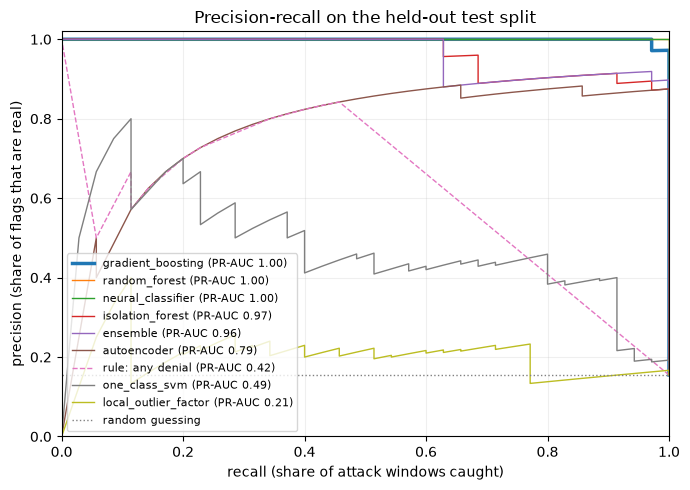

In [7]:
fig, ax = plt.subplots(figsize=(7, 5))
for name in results.index:
    precision, recall, _ = precision_recall_curve(y[idx["test"]], test_scores[name])
    ax.plot(recall, precision, lw=2.5 if name == learned.index[0] else 1, ls="--" if name == RULE else "-",
            label=f"{name} (PR-AUC {results.loc[name, 'test_pr_auc']:.2f})")
ax.axhline(y[idx["test"]].mean(), color="grey", ls=":", lw=1, label="random guessing")
ax.set_xlabel("recall (share of attack windows caught)"); ax.set_ylabel("precision (share of flags that are real)")
ax.set_title("Precision-recall on the held-out test split"); ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
ax.legend(fontsize=8, loc="lower left"); ax.grid(alpha=0.2)
plt.tight_layout(); plt.show()

### How sure are these numbers?

The test split holds a limited number of attack windows, so each score has real uncertainty. Resampling the test windows 1,000 times (bootstrap) gives a 95% interval for PR-AUC. Where two detectors' intervals overlap heavily, treat them as tied.

In [8]:
rng = np.random.default_rng(SEED)
y_test = y[idx["test"]]
intervals = {}
for name in [*learned.index[:4], RULE]:
    scores, samples = test_scores[name], []
    for _ in range(1000):
        pick = rng.integers(0, len(y_test), len(y_test))
        if y_test[pick].any() and not y_test[pick].all():
            samples.append(average_precision_score(y_test[pick], scores[pick]))
    low, high = np.percentile(samples, [2.5, 97.5])
    intervals[name] = {"test PR-AUC": results.loc[name, "test_pr_auc"], "95% low": low, "95% high": high}
pd.DataFrame(intervals).T

,test PR-AUC,95% low,95% high
gradient_boosting,0.999,0.996,1.000
random_forest,1.000,1.000,1.000
neural_classifier,1.000,1.000,1.000
isolation_forest,0.966,0.921,0.997
rule: any denial,0.416,0.257,0.614


## 4. Which attacks get caught

Recall on test, per attack type, for each kind of detector at its validation threshold.

In [9]:
test_types = data.loc[idx["test"], "attack_type"].to_numpy()
per_type = {}
for name in results.index:
    flagged = test_scores[name] >= thresholds[name]
    per_type[name] = {t: flagged[test_types == t].mean() for t in sorted(set(test_types) - {"none"})}
    per_type[name]["normal windows flagged"] = flagged[test_types == "none"].mean()
pd.DataFrame(per_type).T

,cross_tenant,cross_tenant+probing,cross_tenant+refund_drain,enumeration,enumeration+probing,hijacked,probing,prod_write,refund_drain,normal windows flagged
gradient_boosting,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.889,0.000
random_forest,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.000,0.000
neural_classifier,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.889,0.000
isolation_forest,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.000,0.031
ensemble,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.889,0.021
autoencoder,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.889,0.026
rule: any denial,1.0,1.0,1.0,0.0,1.0,1.0,1.0,1.0,0.000,0.016
one_class_svm,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.667,0.251
local_outlier_factor,0.5,0.0,0.0,0.3,0.0,0.0,0.0,1.0,0.000,0.141


## 5. Attacks the model has never seen

Supervised models learn the attacks they were shown. To measure what happens with a *new* kind, each stealth attack type is left out of training in turn, and recall is measured on that type alone. Unsupervised detectors don't use labels, but leaving the type out of their training history still matters: they can't learn it as "normal" either.

Recall on **validation** feeds model selection in section 6. Recall on **test** is shown for information only, so test data never influences which model is chosen.

In [10]:
STEALTH = ["enumeration", "refund_drain", "probing", "cross_tenant"]
unseen_val, unseen_test = {}, {}
for kind in STEALTH:
    has_kind = data["attack_type"].str.contains(kind).to_numpy()
    train_idx = idx["train"][~has_kind[idx["train"]]]  # this attack type never seen in training
    others_val = idx["validation"][~has_kind[idx["validation"]]]
    kind_val, kind_test = idx["validation"][has_kind[idx["validation"]]], idx["test"][has_kind[idx["test"]]]
    if not len(kind_val):
        continue
    unseen_val[kind], unseen_test[kind] = {}, {}
    for name in learned.index:
        detector = DETECTORS[name](seed=SEED)
        detector.fit(X[train_idx], y[train_idx] if detector.supervised else None)
        threshold = best_f1_threshold(y[others_val], detector.score(X[others_val]))
        unseen_val[kind][name] = float((detector.score(X[kind_val]) >= threshold).mean())
        if len(kind_test):
            unseen_test[kind][name] = float((detector.score(X[kind_test]) >= threshold).mean())
unseen_val, unseen_test = pd.DataFrame(unseen_val), pd.DataFrame(unseen_test)
unseen_val["mean"], unseen_test["mean"] = unseen_val.mean(axis=1), unseen_test.mean(axis=1)
pd.concat({"validation (used to choose)": unseen_val, "test (information only)": unseen_test}, axis=1).round(2)

validation (used to choose)                       \
                                     enumeration refund_drain probing   
gradient_boosting                            0.0         0.67    0.88   
random_forest                                0.0         0.00    1.00   
neural_classifier                            1.0         1.00    0.88   
isolation_forest                             0.3         1.00    1.00   
ensemble                                     1.0         1.00    1.00   
autoencoder                                  1.0         1.00    1.00   
one_class_svm                                1.0         1.00    1.00   
local_outlier_factor                         1.0         1.00    1.00   

                                        test (information only)               \
                     cross_tenant  mean             enumeration refund_drain   
gradient_boosting            0.00  0.39                    0.09          0.6   
random_forest                0.00  0.25                    0.09          0.1   
neural_classifier            0.86  0.93                    1.00          0.8   
isolation_forest             0.00  0.57                    0.45          1.0   
ensemble                     1.00  1.00                    1.00          1.0   
autoencoder                  1.00  1.00                    1.00          0.8   
one_class_svm                1.00  1.00                    1.00          1.0   
local_outlier_factor         1.00  1.00                    0.73          1.0   

                                                 
                     probing cross_tenant  mean  
gradient_boosting       0.86         0.33  0.47  
random_forest           0.86         0.33  0.35  
neural_classifier       1.00         1.00  0.95  
isolation_forest        1.00         0.67  0.78  
ensemble                1.00         1.00  1.00  
autoencoder             1.00         1.00  0.95  
one_class_svm           1.00         1.00  1.00  
local_outlier_factor    1.00         1.00  0.93

### What the best detector relies on

Permutation importance on validation: shuffle one feature at a time and see how much PR-AUC falls. A big drop means the detector depends on that feature.

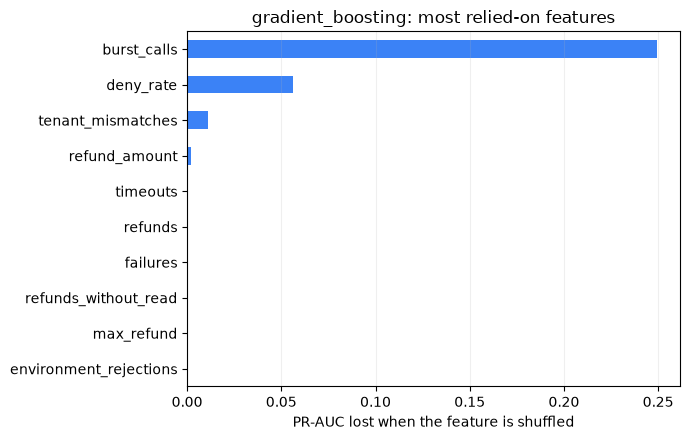

In [11]:
best = fitted[learned.index[0]]  # the strongest on known attacks; section 6 weighs robustness too
xv, yv = X[idx["validation"]], y[idx["validation"]]
base = average_precision_score(yv, best.score(xv))
drops = {}
for j, feature in enumerate(FEATURES):
    losses = []
    for _ in range(5):
        shuffled = xv.copy()
        shuffled[:, j] = rng.permutation(shuffled[:, j])
        losses.append(base - average_precision_score(yv, best.score(shuffled)))
    drops[feature] = float(np.mean(losses))
importance = pd.Series(drops).sort_values()
fig, ax = plt.subplots(figsize=(7, 4.5))
importance.tail(10).plot.barh(ax=ax, color="#3b82f6")
ax.set_xlabel("PR-AUC lost when the feature is shuffled"); ax.set_title(f"{learned.index[0]}: most relied-on features")
ax.grid(axis="x", alpha=0.2); plt.tight_layout(); plt.show()

## 6. Choose, check the production path, refit and save

**Choosing.** Each detector gets a selection score: half its validation PR-AUC (how well it handles the attacks we know) and half its mean validation recall on unseen attack types (how well it copes with new ones). A model that only memorises known attack scripts shouldn't win.

**Thresholds** come from validation, with two meanings:
- **high** is the F1-optimal threshold: a window over it is likely an attack;
- **elevated** is lower, set to catch 95% of validation attacks: worth a look. When the F1-optimal threshold already catches that many, the two coincide and every flag is shown as high.

**Production path.** The console doesn't show the raw detector score. It shows a risk level that can also be raised by the robust per-feature deviation check, which catches never-seen behaviour but can add false alarms. Whether that check stays on is decided on validation, by F1 of "risk above normal".

Then the model is refit on train + validation, with the thresholds carried over as positions within the training scores. The saved artifact is scored through the same load path the console uses, on the untouched test split.

In [12]:
from agentguard.ml.model import load, save, score_windows, train

selection = pd.DataFrame({
    "val_pr_auc": learned["val_pr_auc"],
    "unseen_recall_val": unseen_val["mean"].reindex(learned.index).fillna(0),
})
selection["selection_score"] = 0.5 * selection["val_pr_auc"] + 0.5 * selection["unseen_recall_val"]
selection = selection.sort_values("selection_score", ascending=False)
winner = selection.index[0]
print(f"chosen: {winner}")
selection.round(3)

chosen: ensemble


,val_pr_auc,unseen_recall_val,selection_score
detector,,,
ensemble,0.939,1.000,0.970
neural_classifier,0.988,0.933,0.960
autoencoder,0.822,1.000,0.911
isolation_forest,0.956,0.575,0.765
one_class_svm,0.456,1.000,0.728
gradient_boosting,1.000,0.385,0.693
local_outlier_factor,0.295,1.000,0.648
random_forest,1.000,0.250,0.625


In [13]:
def thresholds_from(y_true, scores):
    high = best_f1_threshold(y_true, scores)
    _, recall, cuts = precision_recall_curve(y_true, scores)
    catching = [t for r, t in zip(recall[:-1], cuts, strict=True) if r >= 0.95]
    elevated = min(max(catching), high) if catching else high
    return elevated, high


def flags(model, frame):
    return pd.DataFrame(score_windows(model, to_windows(frame)))["risk"].to_numpy()


supervised = DETECTORS[winner].supervised
train_rows, val_rows = data.iloc[idx["train"]], data.iloc[idx["validation"]]
draft = train(to_windows(train_rows), min_windows=50, detector=winner,
              labels=list(y[idx["train"]]) if supervised else None, window=WINDOW)
draft.thresholds = thresholds_from(y[idx["validation"]], draft.detector.score(X[idx["validation"]]))

path_check = {}
for use_deviation in (True, False):
    draft.use_deviation = use_deviation
    risk = flags(draft, val_rows)
    path_check[f"deviation check {'on' if use_deviation else 'off'}"] = at_threshold(
        y[idx["validation"]], (risk != "normal").astype(float), 0.5)
path_check = pd.DataFrame(path_check).T
use_deviation = bool(path_check.loc["deviation check on", "f1"] > path_check.loc["deviation check off", "f1"])
print(f"deviation check: {'kept' if use_deviation else 'switched off'} (validation F1 decides)")
path_check.round(3)

deviation check: switched off (validation F1 decides)


,precision,recall,f1,false_positive_rate,accuracy
deviation check on,0.696,1.0,0.821,0.071,0.939
deviation check off,0.914,1.0,0.955,0.015,0.987


In [14]:
# Where the thresholds sit among the training scores, so they mean the same after refitting.
train_sorted = np.sort(draft.detector.score(X[idx["train"]]))
pos = [float(np.searchsorted(train_sorted, t, side="left") / len(train_sorted)) for t in draft.thresholds]

fit_idx = np.concatenate([idx["train"], idx["validation"]])
model = train(to_windows(data.iloc[fit_idx]), min_windows=50, detector=winner,
              labels=list(y[fit_idx]) if supervised else None, window=WINDOW)
model.thresholds = tuple(float(np.quantile(model.train_scores, min(p, 1.0))) for p in pos)
model.use_deviation = use_deviation

# Final, untouched test split, through the production scoring path.
test_rows = data.iloc[idx["test"]]
risk = flags(model, test_rows)
test_score = model.detector.score(X[idx["test"]])
any_flag = at_threshold(y[idx["test"]], (risk != "normal").astype(float), 0.5)
high_flag = at_threshold(y[idx["test"]], (risk == "high").astype(float), 0.5)
model.metrics = {
    "detector": winner, "selection_score": float(selection.loc[winner, "selection_score"]),
    "test_windows": len(idx["test"]), "test_attack_windows": int(y[idx["test"]].sum()),
    "test_pr_auc": float(average_precision_score(y[idx["test"]], test_score)),
    "test_roc_auc": float(roc_auc_score(y[idx["test"]], test_score)),
    "test_precision": any_flag["precision"], "test_recall": any_flag["recall"], "test_f1": any_flag["f1"],
    "test_false_positive_rate": any_flag["false_positive_rate"],
    "test_high_precision": high_flag["precision"], "test_high_recall": high_flag["recall"],
    "test_unseen_recall": float(unseen_test["mean"].get(winner, float("nan"))),
    "use_deviation": use_deviation,
}
digest = save(model, MODEL_PATH)
assert load(MODEL_PATH).detector_name == winner  # the console loads exactly this
print(f"saved {winner} to {MODEL_PATH} (sha256 {digest[:12]}…); "
      f"thresholds elevated ≥ {model.thresholds[0]:.4f}, high ≥ {model.thresholds[1]:.4f}")
pd.Series(model.metrics).to_frame("held-out test, production scoring path")

saved ensemble to ..\models\anomaly.joblib (sha256 fb374cf10e05…); thresholds elevated ≥ 0.8651, high ≥ 0.8651


,"held-out test, production scoring path"
detector,ensemble
selection_score,0.97
test_windows,226
test_attack_windows,35
test_pr_auc,0.959
test_roc_auc,0.993
test_precision,0.895
test_recall,0.971
test_f1,0.932
test_false_positive_rate,0.021


In [15]:
# Risk level by what each test window really was.
outcome = pd.crosstab(test_rows["attack_type"].to_numpy(), risk, rownames=["window"], colnames=["risk shown"])
outcome.reindex(columns=["normal", "elevated", "high"], fill_value=0)

risk shown,normal,elevated,high
window,,,
cross_tenant,0,0,4
cross_tenant+probing,0,0,1
cross_tenant+refund_drain,0,0,1
enumeration,0,0,10
enumeration+probing,0,0,1
hijacked,0,0,2
none,187,0,4
probing,0,0,5
prod_write,0,0,2


## 7. Optional: a plain-English explanation from Gemini

If `GEMINI_API_KEY` is set, Gemini summarises the riskiest test window for an operator, from the model's top deviating features. The LLM only *explains*; it doesn't score or decide anything. Skipped without a key.

In [16]:
if os.environ.get("GEMINI_API_KEY") or os.environ.get("GOOGLE_API_KEY"):
    from google import genai

    scored = pd.DataFrame(score_windows(model, to_windows(test_rows)))
    worst = scored.sort_values("score", ascending=False).iloc[0]
    prompt = (
        "You help a security operator triage AI-agent behaviour. In two sentences, say what this "
        f"one-minute window of agent '{test_rows.iloc[int(worst.name)]['agent']}' suggests and what to check first. "
        f"Risk: {worst['risk']}. Most unusual features (deviation from normal in robust units): {worst['drivers']}."
    )
    reply = genai.Client().models.generate_content(model=os.environ.get("GEMINI_MODEL", "gemini-2.5-flash"), contents=prompt)
    print(reply.text)
else:
    print("GEMINI_API_KEY not set: skipped.")

GEMINI_API_KEY not set: skipped.


## Limits, stated plainly

- **The attacks are scripted.** Labels come from the traffic generator, so these numbers measure detection of *these* behaviours (enumeration, refund draining, probing, cross-tenant reads, hijacked-agent bursts) in *this* simulated fleet. Real agents and real attackers will differ; retrain and re-evaluate on your own traffic.
- **Supervised detectors are strongest on attacks like their training data** and weaker on new kinds (section 5). The ensemble keeps an unsupervised member for that reason.
- **"Normal" is whatever the training window contained.** Unsupervised detectors train on unlabelled history, so abuse that was already common looks normal.
- **Advisory only.** The score is shown to operators in the console and never allows or denies a call.